### PY-PDE Tutorials

In [1]:
import pde
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dolfin import *
import matplotlib as mpl
import os

  0%|          | 0/1.0 [00:00<?, ?it/s]

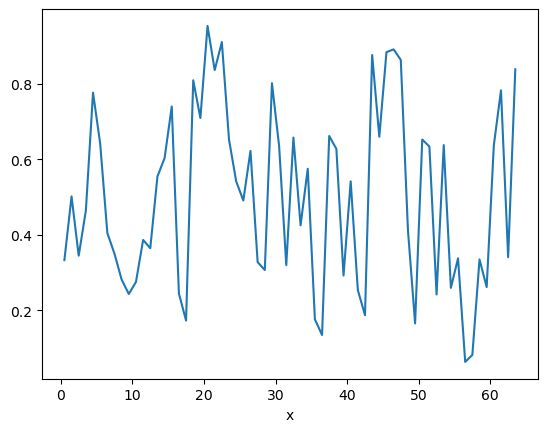

In [10]:
# 1. Define a one-dimensional domain with 64 support points
grid = pde.UnitGrid([64])

# 2. Create an initial scalar field with random values
state = pde.ScalarField.random_uniform(grid, vmin=0, vmax=1)

# 3. Define a simple PDE (diffusion equation)
eq = pde.DiffusionPDE(diffusivity=0.1)

# 4. Evolve the field in time
result = eq.solve(state, t_range=1, dt=1e-3)

# 5. Inspect the final state
result.plot()

  0%|          | 0/100.0 [00:00<?, ?it/s]

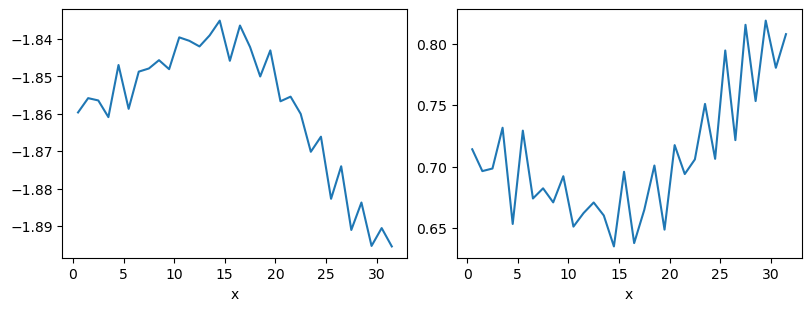

In [110]:
from pde import FieldCollection, PDEBase, UnitGrid


class FitzhughNagumoPDE(PDEBase):
    """FitzHugh–Nagumo model with diffusive coupling."""

    def __init__(self, stimulus=0.5, τ=10, a=0, b=0, bc="auto_periodic_neumann"):
        super().__init__()
        self.bc = bc
        self.stimulus = stimulus
        self.τ = τ
        self.a = a
        self.b = b

    def evolution_rate(self, state, t=0):
        v, w = state  # membrane potential and recovery variable

        v_t = v.laplace(bc=self.bc) + v - v**3 / 3 - w + self.stimulus
        w_t = (v + self.a - self.b * w) / self.τ

        return FieldCollection([v_t, w_t])


grid = UnitGrid([32])
state = FieldCollection.scalar_random_uniform(2, grid)

eq = FitzhughNagumoPDE()
result = eq.solve(state, t_range=100, dt=0.01)
result.plot()

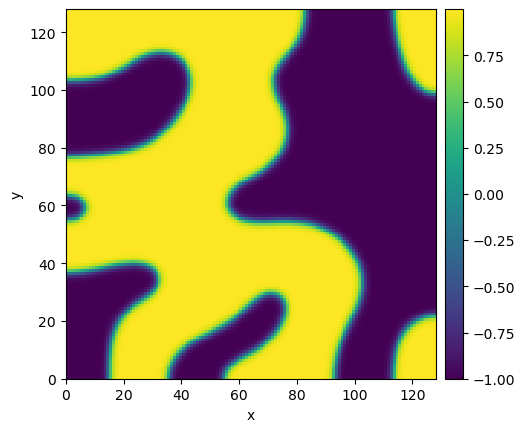

In [259]:
from pde import AllenCahnPDE, FileStorage, MovieStorage, ScalarField, UnitGrid

# initialize the model
np.random.seed(42)
state = ScalarField.random_uniform(UnitGrid([128, 128]), -0.01, 0.01)
eq = AllenCahnPDE()

# initialize empty storages
file_write = FileStorage("allen_cahn.hdf")
movie_write = MovieStorage("allen_cahn.avi", vmin=-1, vmax=1)

# store trajectory in storage
final_state = eq.solve(
    state,
    t_range=100,
    adaptive=True,
    tracker=[file_write.tracker(2), movie_write.tracker(1)],
)

# read storage and plot last frame
movie_read = MovieStorage("allen_cahn.avi")
movie_read[-1].plot()

  0%|          | 0/100.0 [00:00<?, ?it/s]

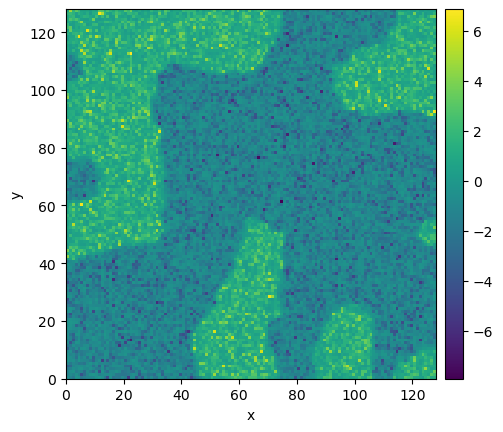

In [260]:
from pde import PDE, ScalarField, UnitGrid


class AllenCahnNoisePDE(PDE):
    """Allen–Cahn PDE with custom noise implementation."""

    use_noise_variance = True

    def make_noise_variance(self, state, *, backend, ret_diff=False):
        """Make function that calculates noise variance."""
        noise = float(self.noise)

        if ret_diff:

            def noise_variance(state_data, t):
                return noise * state_data**2, 2 * noise * state_data

        else:

            def noise_variance(state_data, t):
                return noise * state_data**2

        return noise_variance


eq = AllenCahnNoisePDE(
    rhs={"c": "laplace(c) + c - c**3"}, noise=10.0, noise_interpretation="stratonovich"
)
np.random.seed(42)
state = ScalarField.random_uniform(UnitGrid([128, 128]), -0.01, 0.01)
result = eq.solve(state, t_range=100, dt=1e-3, solver="milstein")
result.plot()

  0%|          | 0/30.0 [00:00<?, ?it/s]

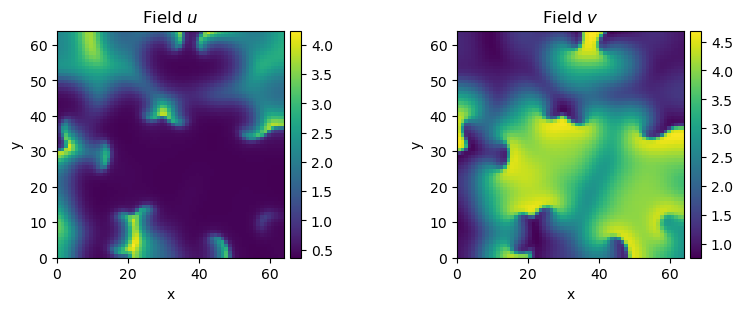

In [22]:
from pde import (
    FieldCollection,
    PlotTracker,
    ReactionDiffusionPDE,
    ScalarField,
    UnitGrid,
)

# define the PDE
a, b = 1, 3
d0, d1 = 1, 0.1
eq = ReactionDiffusionPDE(
    variables=["u", "v"],
    diffusivity=[d0, d1],
    sources=[f"{a} - ({b} + 1) * u + u**2 * v", f"{b} * u - u**2 * v"],
)

# initialize state
grid = UnitGrid([64, 64])
u = ScalarField(grid, a, label="Field $u$")
v = b / a + 0.1 * ScalarField.random_normal(grid, label="Field $v$")
state = FieldCollection([u, v])

# simulate the pde
# tracker = PlotTracker(interrupts=1, plot_args={"vmin": 0, "vmax": 5})
sol = eq.solve(state, t_range=30, dt=1e-3) #  , tracker=tracker)
sol.plot()

### My stuff

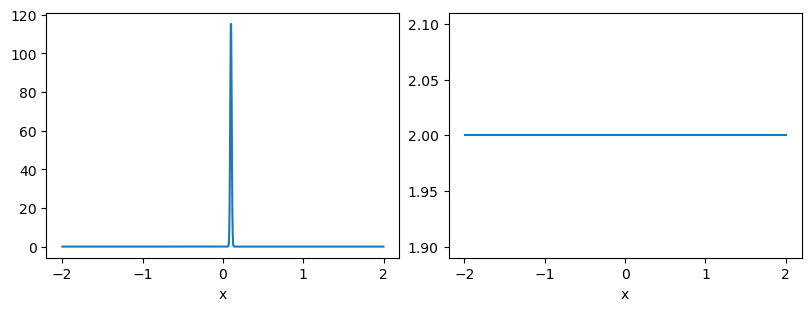

In [164]:
grid = pde.CartesianGrid([[-2, 2]], [1000], periodic=[False])
u0 = ScalarField.from_expression(grid, "118 * exp(-(11800/2)*((x - 0.1) ** 2))")
state = FieldCollection([u0, ScalarField.from_expression(grid, "2")])
state.plot()

In [165]:
def round_to_multiple(number, multiple):
    return multiple * np.round(number / multiple)
def tolerant_mean(arrs):
    lens = [len(i) for i in arrs]
    arr = np.ma.empty((np.max(lens),len(arrs)))
    arr.mask = True
    for idx, l in enumerate(arrs):
        arr[:len(l),idx] = l
    return arr.mean(axis = -1), arr.std(axis=-1)

In [189]:
from pde import FieldCollection, PDEBase, UnitGrid, ScalarField, VectorField, SDEBase, FileStorage, MovieStorage


class BAREPDE(PDEBase):
    """Coupled fungal network SDE."""
    
    def __init__(self, alpha=0.12, beta=0.009, vd=0.02, sg=0.03, D = 0.0002, bc = {"x-": {"value": 0}, "x+": {"value": 0}}):
        super().__init__()
        self.bc = bc
        self.alpha = alpha
        self.beta = beta
        self.vd = vd
        self.sg = sg
        self.D = D

    def evolution_rate(self, state, t=0):
        n, rho = state  # membrane potential and recovery variable
        
        xhat = VectorField(n.grid, [[1, 0, 0][0:n.grid.dim]])  # Unit vector in x
        
        n_t = self.alpha * n - self.beta * n * rho - (n * self.vd * xhat).divergence(bc=self.bc) + self.D * n.laplace(bc=self.bc)
        rho_t = self.sg * n

        return FieldCollection([n_t, rho_t])

class BAREPDE_ext(PDEBase):
    """Coupled fungal network SDE with explicit puller hyphae representation."""
    
    def __init__(self, alpha=0.12, beta=0.009, vd=0.02, sg=0.03, D = 0.0002, K1 = 0.25, K2 = 0.4, vp = 0.03, bc = {"x-": {"value": 0}, "x+": {"value": 0}}):
        super().__init__()
        self.bc = bc
        self.alpha = alpha
        self.beta = beta
        self.vd = vd
        self.sg = sg
        self.D = D

        self.K1 = K1
        self.K2 = K2
        self.vp = vp

    def evolution_rate(self, state, t=0):
        n, np, rho = state  # membrane potential and recovery variable
        
        xhat = VectorField(n.grid, [[1, 0, 0][0:n.grid.dim]])  # Unit vector in x
        
        n_t = self.alpha * n - self.beta * n * rho - K1 * n + K2 * np - (n * self.vd * xhat).divergence(bc=self.bc) + self.D * n.laplace(bc=self.bc)
        np_t = self.alpha * np  + K1 * n - K2 * np - (np * self.vp * xhat).divergence(bc=self.bc)
        rho_t = self.sg * n
        
        return FieldCollection([n_t, np_t, rho_t])

class BARESDE(SDEBase):
    """Coupled fungal network SDE."""
    
    use_noise_variance = True
    
    def __init__(self, alpha=0.12, beta=0.009, vd=0.02, sg=0.03, D = 0.0002, ep = 0.01, noise = 0.1, bc = {"x-": {"value": 0}, "x+": {"value": 0}}):
        super().__init__()
        self.bc = bc
        self.alpha = alpha
        self.beta = beta
        self.vd = vd
        self.sg = sg
        self.D = D
        self.ep = ep
        self.noise = noise
        
    def evolution_rate(self, state, t=0):
        n, rho = state
        xhat = VectorField(n.grid, [[1, 0, 0][0:n.grid.dim]])  # Unit vector in x
        
        n_t = self.alpha * n - self.beta * n * rho - (n * self.vd * xhat).divergence(bc=self.bc) + self.D * n.laplace(bc=self.bc)
        rho_t = self.sg * n

        return FieldCollection([n_t, rho_t])
        
    def make_noise_variance(self, state, backend, ret_diff=False):
        def noise_variance(state_data, t):
            n, rho = state_data
            n_noise = self.noise * (2 * self.ep * np.abs(n)) ** (1 / 2)
            rho_noise = 0 * rho # self.noise * (2 * self.ep * np.abs(rho)) ** (1 / 2)  # Zero noise for rho
            return np.array([n_noise, rho_noise])
            
        return noise_variance

class FKPP(PDEBase):
    """Coupled fungal network SDE."""
    
    def __init__(self, alpha=0.12, beta=0.009, vd=0.02, sg=0.03, D = 0.0002, bc = {"x-": {"value": 0}, "x+": {"value": 0}}):
        super().__init__()
        self.bc = bc
        self.alpha = alpha
        self.beta = beta
        self.vd = vd
        self.sg = sg
        self.D = D

    def evolution_rate(self, state, t=0):
        n, rho = state  # membrane potential and recovery variable
        
        xhat = VectorField(n.grid, [[1, 0, 0][0:n.grid.dim]])  # Unit vector in x
        
        n_t = self.alpha * n * (1 - (n / 100)) + self.D * n.laplace(bc=self.bc)
        rho_t = self.sg * n

        return FieldCollection([n_t, rho_t])
        

Length = 3 # 40.0
left = 1e-3
dX = 0.01
X = np.arange(left, Length, dX)
nx = len(X)
T = 34
nT = int(T * 10) # 900
dt = T / nT

alpha = 0.12
beta = 0.009
vd = 0.02
sg = 0.03
D = 0.0002
A = 118
s = 11800
r0 = 0.1

K1 = 0.6
K2 = 0.4
vp = 0.03

ep = dt
noise = 0.0001

grid = pde.CartesianGrid([[left, Length]], [nx], periodic=[False])
n0 = ScalarField.from_expression(grid, str(A) + " * exp(-(" + str(s) + "/2)*((x - " + str(r0) + ") ** 2))")
np0 = ScalarField.from_expression(grid, "0")
# rho0 = ScalarField.from_expression(grid, "0")
rho0 = ScalarField.from_expression(grid, str(A * sg) + " * exp(-(" + str(A * sg * 100) + "/2)*((x - " + str(r0) + ") ** 2))")
state = FieldCollection([n0, rho0])
state_ext = FieldCollection([n0, np0, rho0])


eq = BAREPDE(alpha = alpha, beta = beta, vd = vd, sg = sg, D = D)
eq_noise = BARESDE(alpha = alpha, beta = beta, vd = vd, sg = sg, D = D, ep = ep, noise = noise)
eq_ext = BAREPDE_ext(alpha = alpha, beta = beta, vd = vd, sg = sg, D = D, K1 = K1, K2 = K2, vp = vp)
eq_FKPP = FKPP(alpha = alpha, beta = beta, vd = vd, sg = sg, D = D)

# storage = pde.MemoryStorage()
# result = eq.solve(state, t_range=100, dt=0.01, tracker=["progress", storage.tracker(10)])
# result.plot()

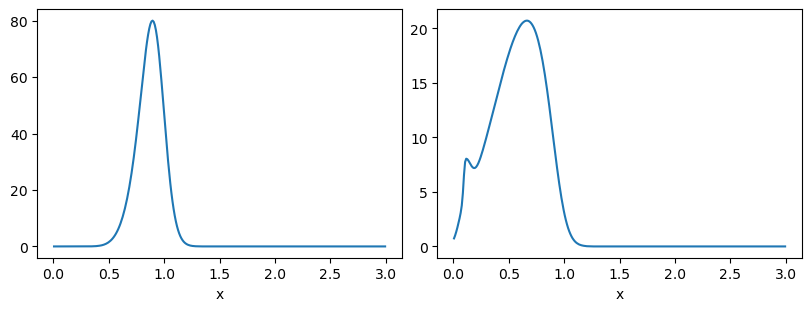

In [193]:
# initialize empty storages
file_write = FileStorage("BARE.hdf")
movie_write = MovieStorage("BARE.avi", vmin=0, vmax= 3 / beta)

# store trajectory in storage
final_state = eq.solve(
    state,
    t_range=T,
    dt=dt,
    adaptive=True,
    tracker=[file_write.tracker(1), movie_write.tracker(1)],
)

# read storage and plot last frame
movie_read = MovieStorage("BARE.avi")
movie_read[-1].plot()

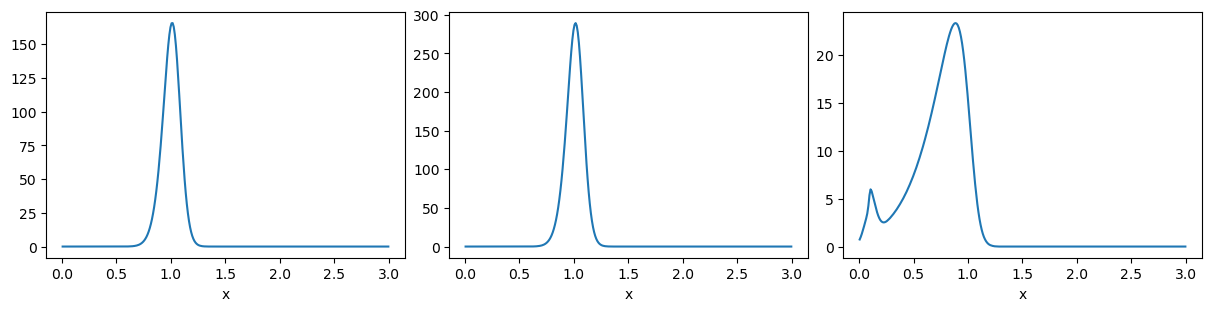

In [184]:
# initialize empty storages
file_write = FileStorage("BARE_ext.hdf")
movie_write = MovieStorage("BARE_ext.avi", vmin=0, vmax= 5 / beta)

# store trajectory in storage
final_state = eq_ext.solve(
    state_ext,
    t_range=T,
    dt=dt,
    adaptive=True,
    tracker=[file_write.tracker(1), movie_write.tracker(1)],
)

# read storage and plot last frame
movie_read = MovieStorage("BARE_ext.avi")
movie_read[-1].plot()

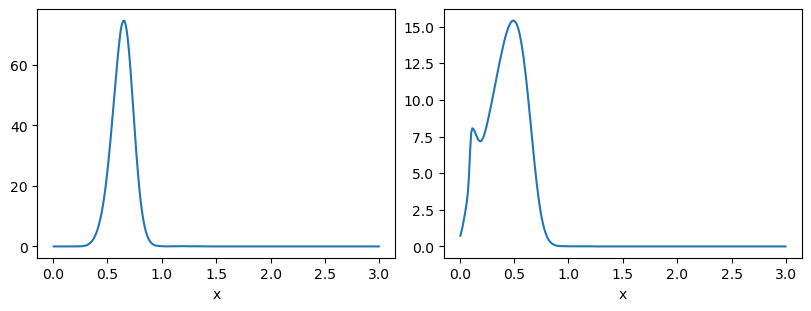

In [185]:
# initialize empty storages
file_write = FileStorage("BARE_noise.hdf")
movie_write = MovieStorage("BARE_noise.avi", vmin=0, vmax= 3 / beta)

# store trajectory in storage
final_state_noise = eq_noise.solve(
    state,
    t_range=T,
    dt=dt,
    adaptive=False,
    tracker=[file_write.tracker(1), movie_write.tracker(1)],
)

# read storage and plot last frame
movie_read = MovieStorage("BARE_noise.avi")
movie_read[-10].plot()

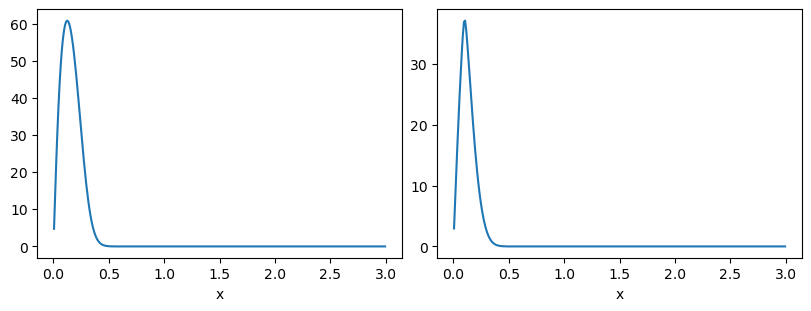

In [191]:
# initialize empty storages
file_write = FileStorage("FKPP.hdf")
movie_write = MovieStorage("FKPP.avi", vmin=0, vmax= 3 / beta)

# store trajectory in storage
final_state_noise = eq_FKPP.solve(
    state,
    t_range=T,
    dt=dt,
    adaptive=False,
    tracker=[file_write.tracker(1), movie_write.tracker(1)],
)

# read storage and plot last frame
movie_read = MovieStorage("FKPP.avi")
movie_read[-10].plot()

In [192]:
field_read = FileStorage("BARE.hdf")
field_read_ext = FileStorage("BARE_ext.hdf")
field_read_noise = FileStorage("BARE_noise.hdf")
field_read_FKPP = FileStorage("FKPP.hdf")

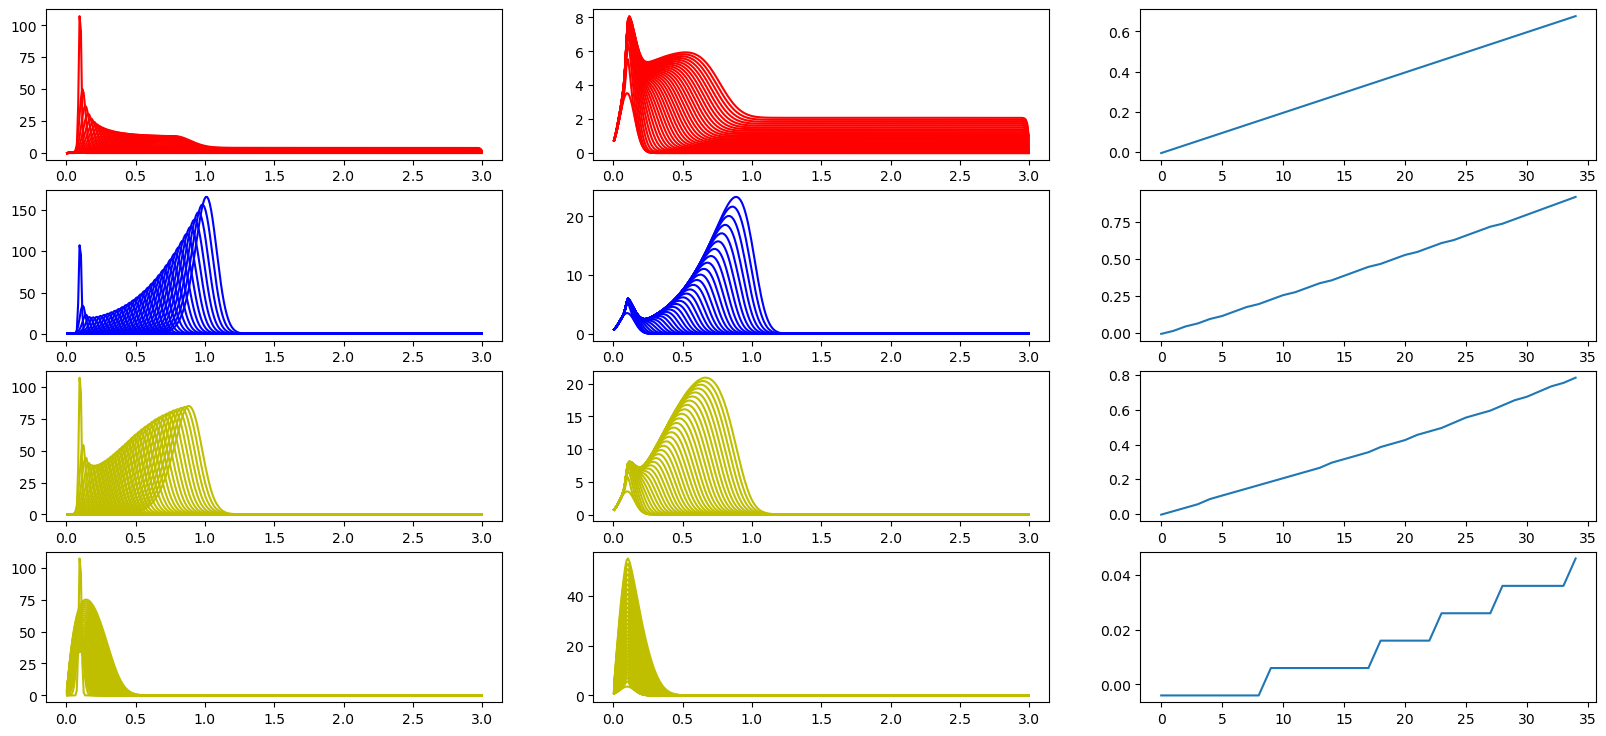

In [194]:
n_t = np.zeros((T + 1, nx))
rho_t = np.zeros((T + 1, nx))
n_sat_r = []
rho_sat_r = []
n_sat_t = []
rho_sat_t = []
x_r = []
dxdt = []
dxdt_ext = []
dxdt_noise = []
dxdt_FKPP = []

fig, ax = plt.subplots(4, 3, figsize = (20, 9))
x_n = field_read[0].get_line_data(index=0, scalar='auto', extract='auto')['data_x']
x_rho = field_read[0].get_line_data(index=1, scalar='auto', extract='auto')['data_x']
x_n_ext = field_read_ext[0].get_line_data(index=0, scalar='auto', extract='auto')['data_x']
x_np_ext = field_read_ext[0].get_line_data(index=1, scalar='auto', extract='auto')['data_x']
x_rho_ext = field_read_ext[0].get_line_data(index=2, scalar='auto', extract='auto')['data_x']
x_n_noise = field_read_noise[0].get_line_data(index=0, scalar='auto', extract='auto')['data_x']
x_rho_noise = field_read_noise[0].get_line_data(index=1, scalar='auto', extract='auto')['data_x']
x_n_FKPP = field_read_FKPP[0].get_line_data(index=0, scalar='auto', extract='auto')['data_x']
x_rho_FKPP = field_read_FKPP[0].get_line_data(index=1, scalar='auto', extract='auto')['data_x']
for i in range(len(field_read_noise)):
    y_n = field_read[i].get_line_data(index=0, scalar='auto', extract='auto')['data_y']
    y_rho = field_read[i].get_line_data(index=1, scalar='auto', extract='auto')['data_y']
    y_n_ext = field_read_ext[i].get_line_data(index=0, scalar='auto', extract='auto')['data_y']
    y_np_ext = field_read_ext[i].get_line_data(index=1, scalar='auto', extract='auto')['data_y']
    y_rho_ext = field_read_ext[i].get_line_data(index=2, scalar='auto', extract='auto')['data_y']
    y_n_noise = field_read_noise[i].get_line_data(index=0, scalar='auto', extract='auto')['data_y']
    y_rho_noise = field_read_noise[i].get_line_data(index=1, scalar='auto', extract='auto')['data_y']
    y_n_FKPP = field_read_FKPP[i].get_line_data(index=0, scalar='auto', extract='auto')['data_y']
    y_rho_FKPP = field_read_FKPP[i].get_line_data(index=1, scalar='auto', extract='auto')['data_y']
    n_t[i, :] = y_n
    rho_t[i, :] = y_rho
    x_t = x_n[np.argmax(y_n)] - r0
    dxdt.append(x_t)
    x_t_ext = x_n_ext[np.argmax(y_n_ext)] - r0
    dxdt_ext.append(x_t_ext)
    x_t_noise = x_n_noise[np.argmax(y_n_noise)] - r0
    dxdt_noise.append(x_t_noise)
    x_t_FKPP = x_n_FKPP[np.argmax(y_n_FKPP)] - r0
    dxdt_FKPP.append(x_t_FKPP)

    n_sat_t.append(np.max(y_n))
    rho_nonzero = y_rho[y_rho > 0.1]
    if len(rho_nonzero) > 0:
        rho_sat_t.append(np.median(rho_nonzero))
    else:
        rho_sat_t.append(0)

    
    if round(x_t, 2) % 0.05 <= 0.02: # check if made it to new ring
        if round_to_multiple(x_t, 0.05) not in x_r:
            n_sat_r.append(np.max(y_n))
            if len(rho_nonzero) > 0:
                rho_sat_r.append(np.median(rho_nonzero))
            else:
                rho_sat_r.append(0)
            x_r.append(round_to_multiple(x_t, 0.05))
    
    ax[0, 0].plot(x_n,y_n, color = 'r')
    ax[0, 1].plot(x_rho,y_rho, color = 'r')
    ax[1, 0].plot(x_n_ext,y_n_ext, color = 'b')
    ax[1, 1].plot(x_rho_ext,y_rho_ext, color = 'b')
    ax[2, 0].plot(x_n_noise,y_n_noise, color = 'y')
    ax[2, 1].plot(x_rho_noise,y_rho_noise, color = 'y')
    ax[3, 0].plot(x_n_FKPP,y_n_FKPP, color = 'y')
    ax[3, 1].plot(x_rho_FKPP,y_rho_FKPP, color = 'y')

x_r = np.array(list(x_r))

data_t = pd.DataFrame({'n': np.array(n_sat_t), 'rho': np.array(rho_sat_t), 'c': dxdt, 't': np.arange(T + 1)})
data_r = pd.DataFrame({'n': np.array(n_sat_r), 'rho': np.array(rho_sat_r), 'r': x_r})

if data_r['r'].max() < 0.95:
    for r in np.arange(data_r['r'].max() + 0.05, 1.05, 0.05):
        data_r.loc[len(data_r)] = [0, 0, round_to_multiple(r, 0.05)]


ax[0, 2].plot(np.arange(T + 1), dxdt)
ax[1, 2].plot(np.arange(T + 1), dxdt_ext)
ax[2, 2].plot(np.arange(T + 1), dxdt_noise)
ax[3, 2].plot(np.arange(T + 1), dxdt_FKPP)

### Monte Carlo Simulation

In [5]:
plot = 0
if plot == 1:
    fig, axs = plt.subplots(2, M, figsize = (50, 7))

for m in range(M):
    alpha_test = 0.12
    beta_test = 0.009
    vd_test = 0.02
    sg_test = 0.03
    D_test = 0.0002
    upar = [118, 11800, 0.1]
    noise_std = 0.1
    
    set_log_active(False)
    
    cmap2 = mpl.colormaps["spring"]
    cmap = mpl.colormaps["winter"]
    
    # Define the problem
    Length = 3
    left = 1e-3 # small positive left end to avoid 1/x singularity
    nx = Length * 50
    T = 50 # (hours)
    nT = T * 10
    keep = 10
    mesh = IntervalMesh(nx, left, Length)
    P1 = FiniteElement('P', interval, 1)
    element = MixedElement([P1, P1])
    V = FunctionSpace(mesh, element)
    M = 50

    
    density_tip = np.zeros((int(nT / keep), nx, M))
    density_in = np.zeros((int(nT / keep), nx, M))
    
    # Define the parameters
    
    dt = T / nT
    alphval = alpha_test
    cval = 0.6
    
    # Define the initial condition
    u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
    u0 = Expression((u0_str, '0.0'), degree=1)
    
    # define radial coordinate
    rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
    r = interpolate(rexp, V)
    invr, _ = split(r)
    
    # Define other elements
    u_n = interpolate(u0, V)
    u = Function(V)
    n, rho = split(u)
    n_n, rho_n = split(u_n) 
    v_1, v_2 = TestFunctions(V)
    k = Constant((1,))
    
    s_scal = Constant(sg_test)
    beta = Constant(beta_test)
    alpha = Constant(alphval)
    D = Constant(D_test)
    
    n_mid = 0.5 * (n_n + n)
    v_sval = vd_test # 0.014
    v_s = Constant((v_sval,))
    
    F = n * v_1 * dx - n_n * v_1 * dx
    # Diffusion term
    F += D * dot(grad(n), grad(v_1)) * dt * dx
    # Cylindrical correction terms using invr
    F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
    F += dt * dot(grad(n_mid), v_s) * v_1 * dx
    F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx
    
    F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
    F += beta * v_1 * rho * n * dt * dx
    F -= alpha * n * v_1 * dt * dx
    
    # Apply the boundary conditions (left=left, right=Length)
    u_L = (Constant(0.0), Constant(0.0))
    u_R = (Constant(0.0), Constant(0.0))
    bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
    bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
    bcs = [bc_L, bc_R]
    
    t = 0.0
    a, L = lhs(F), rhs(F)
    V2 = FunctionSpace(mesh, 'P', 1)
    X = np.linspace(left, Length, nx)
    poss = []

    i=0
    for t in np.linspace(0, T, nT):
        solve(F == 0, u, bcs)

        # u_n.assign(u)
        # Add white noise
        _n, _rho = u.split()
        _n.vector()[:] += np.random.normal(0, noise_std, len(_n.vector())) * np.sqrt(np.abs(_n.vector()[:]) * dt)
        _n.vector()[:] = np.clip(_n.vector()[:], 0, None)
        _rho.vector()[:] = np.clip(_rho.vector()[:], 0, None)
        
        assign(u_n.sub(0), _n)
        assign(u_n.sub(1), _rho)
        n_field = interpolate(_n, V2)
        
        if i % keep == 0:
            rho_field = interpolate(_rho, V2)
            if plot == 1:
                axs[0, m].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
                axs[1, m].plot(X, [rho_field(x) for x in X], color=cmap(t / T))
    
            density_tip[int(i / keep), :, m] = [n_field(x) for x in X]
            density_in[int(i / keep), :, m] = [rho_field(x) for x in X]
            # if i > nT / 2:
            #     axs[2, m].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
        poss.append(np.argmax([n_field(x) for x in X]))
        i += 1

# axs[0].set_xlabel('')
# axs[0].set_ylabel('$n (mm^{-2})$')
# axs[1].set_xlabel('position ($mm$)')
# axs[1].set_ylabel(r'$\rho (mm.mm^{-2})$')

Form has no parts with arity 2.
Form has no parts with arity 2.
Form has no parts with arity 2.
Form has no parts with arity 2.
Form has no parts with arity 2.


KeyboardInterrupt: 

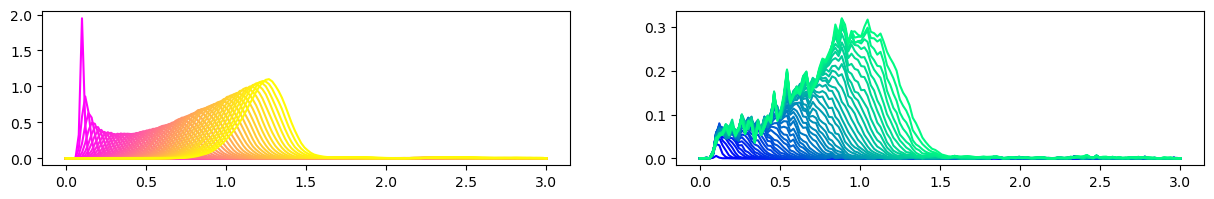

In [75]:
density_tip_avg = np.mean(density_tip, axis = 2)
density_in_avg = np.mean(density_in, axis = 2)
fig, axs = plt.subplots(1, 2, figsize = (15, 2))
for t in range(T):
    axs[0].plot(X, density_tip_avg[t, :], color=cmap2(t / T))
    axs[1].plot(X, density_in_avg[t, :], color=cmap(t / T))

Form has no parts with arity 2.
Calling FFC just-in-time (JIT) compiler, this may take some time.
Calling FFC just-in-time (JIT) compiler, this may take some time.


NameError: name 'round_to_multiple' is not defined

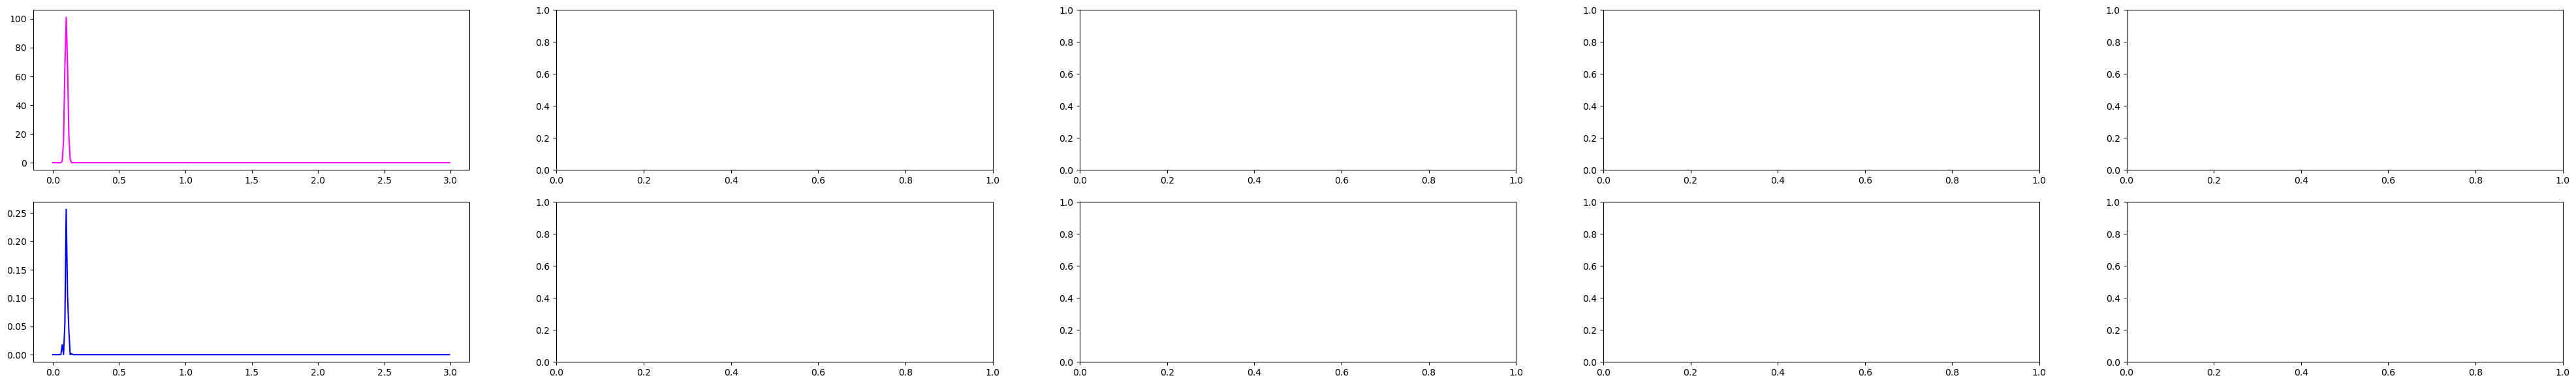

In [6]:
alpha_test = 0.12
beta_test = 0.009
vd_test = 0.02
sg_test = 0.03
D_test = 0.0002
upar = [118, 11800, 0.1]

plot = 1
alphval = alpha_test
beta = beta_test
v_sval = vd_test
s_scal = sg_test
D = D_test
eta_std = 1

cmap2 = mpl.colormaps["spring"]
cmap = mpl.colormaps["winter"]
set_log_level(LogLevel.WARNING)
M = 5

# Define the problem
T = 34 # 90
dt = T/nT
Length = 3 # 40.0
left = 1e-3
dX = 0.01
X = np.arange(left, Length, dX)
nx = len(X)
nT = int(T * 10) # 900
keep = 10 # get every hour

density_tip_t = np.zeros((int(nT / keep), nx, M))
density_in_t = np.zeros((int(nT / keep), nx, M))
density_tip_r = []
density_in_r = []

n_sat_r = []
rho_sat_r = []

if plot == 1:
    fig, axs = plt.subplots(2, M, figsize = (10 * M, 7))

for m in range(M):
    x_r = []
    density_tip_r.append([])
    density_in_r.append([])
    mesh = IntervalMesh(nx, left, Length)
    P1 = FiniteElement('P', interval, 1)
    element = MixedElement([P1, P1])
    V = FunctionSpace(mesh, element)
    
    # alphval = 0.039
    cval = 0.6
    # Define the initial condition
    u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
    u0 = Expression((u0_str, '0.0'), degree=1)
    #define radial coordinate
    rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
    r = interpolate(rexp, V)
    invr, _ = split(r)
    # Define other elements

    u_n = interpolate(u0, V)
    u = Function (V)
    n, rho = split(u)
    n_n, rho_n= split(u_n)
    v_1, v_2 = TestFunctions(V)
    k = Constant((1,))

    # s_scal =  Constant(0.0288) # Constant(0.2)
    # beta = Constant(0.022)
    alpha = Constant(alphval)
    # D = Constant(0.02)

    n_mid = 0.5*(n_n + n)
    # v_sval = 0.235
    v_s = Constant((v_sval,))

    F = n * v_1 * dx - n_n * v_1 * dx
    # Diffusion term
    F += D * dot(grad(n), grad(v_1)) * dt * dx
    # Cylindrical correction terms using invr
    F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
    F += dt * dot(grad(n_mid), v_s) * v_1 * dx
    F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

    F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
    F += beta * v_1 * rho * n * dt * dx
    F -= alpha * n * v_1 * dt * dx

    # Apply the boundary conditions (left=left, right=Length)
    u_L = (Constant(0.0), Constant(0.0))
    u_R = (Constant(0.0), Constant(0.0))
    bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
    bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
    bcs = [bc_L, bc_R]

    t = 0.0
    a, L = lhs(F), rhs(F)
    V2 = FunctionSpace(mesh, 'P', 1)
    # X = np.arange(left, Length, dx)
    poss = []

    i=0
    for t in np.linspace(0,T,nT):
        try:
            solve(F==0, u,bcs)
            # Add white noise
            _n, _rho = u.split()
            _n.vector()[:] += np.random.normal(0, eta_std, len(_n.vector())) * np.sqrt(np.abs(_n.vector()[:]) * dt)
            _n.vector()[:] = np.clip(_n.vector()[:], 0, None)
            _rho.vector()[:] = np.clip(_rho.vector()[:], 0, None)
            
            assign(u_n.sub(0), _n)
            assign(u_n.sub(1), _rho)
            n_field = interpolate(_n, V2)

            if i%keep==0:# i%100==0:
                n_field = interpolate(_n, V2)
                rho_field = interpolate(_rho, V2)
                density_tip_t[int(i / keep), :, m] = [n_field(x) for x in X]
                density_in_t[int(i / keep), :, m] = [rho_field(x) for x in X]
                if plot == 1:
                    axs[0, m].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
                    axs[1, m].plot(X, [rho_field(x) for x in X], color=cmap(t / T))

            xi = np.argmax([n_field(x) for x in X]) * (Length / nx) - upar[2]
            if round(xi, 2) % 0.05 <= 0.02:
                if round_to_multiple(xi, 0.05) not in x_r:
                    density_tip_r[m].append([n_field(x) for x in X])
                    density_in_r[m].append([rho_field(x) for x in X])
                    x_r.append(round_to_multiple(xi, 0.05))

        except RuntimeError as e:
            print('hour ' + str(t))
            print(e)
            if i%keep==0:# i%100==0:
                density_tip_t[int(i / keep), :] = np.zeros(len(X))
                density_in_t[int(i / keep), :] = np.zeros(len(X))
        i += 1
    print(x_r)

tip_r_avg = np.mean(np.array(density_tip_r), axis = 0)
in_r_avg = np.mean(np.array(density_in_r), axis = 0)

for r in np.arange(len(x_r)):
    n_sat_r.append(np.max(tip_r_avg[int(r)]))
    rho_nonzero = in_r_avg[int(r)][in_r_avg[int(r)] > 0.1]
    if len(rho_nonzero) > 0:
        rho_sat_r.append(np.median(rho_nonzero))
    else:
        rho_sat_r.append(0)

n_sat_t = []
rho_sat_t = []

tip_t_avg = np.mean(density_tip_t, axis = 2)
in_t_avg = np.mean(density_in_t, axis = 2)

for t in np.arange(T):
    # collect PDE output for each hour
    # saturation density
    n_sat_t.append(np.max(density_tip_avg[t, :]))
    poss.append(np.argmax(density_tip_avg[t, :]))
    rho_nonzero = density_in_avg[t, :][density_in_avg[t, :] > 0.1]
    if len(rho_nonzero) > 0:
        rho_sat_t.append(np.median(rho_nonzero))
    else:
        rho_sat_t.append(0)

dxdt = np.array(poss)*Length/nx - upar[2]
x_r = np.array(list(x_r))

data_t = pd.DataFrame({'n': np.array(n_sat_t), 'rho': np.array(rho_sat_t), 'c': dxdt, 't': np.arange(T)})
data_r = pd.DataFrame({'n': np.array(n_sat_r), 'rho': np.array(rho_sat_r), 'r': x_r})

if data_r['r'].max() < 0.95:
    for r in np.arange(data_r['r'].max() + 0.05, 1.05, 0.05):
        data_r.loc[len(data_r)] = [0, 0, round_to_multiple(r, 0.05)]

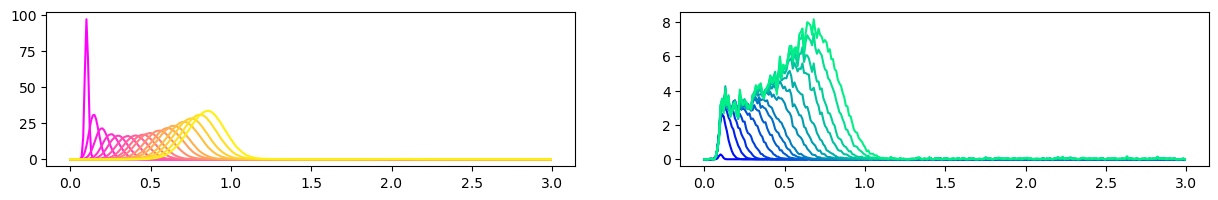

In [162]:
fig, axs = plt.subplots(1, 2, figsize = (15, 2))
for r in range(len(x_r)):
    axs[0].plot(X, tip_r_avg[r, :], color = cmap2(r/len(x_r)))
    axs[1].plot(X, in_r_avg[r, :], color = cmap(r/len(x_r)))